# Machine Learning Assignment – Airline Passenger Satisfaction Classification
**Programme:** M.Tech (AIML / DSE) – Machine Learning

**Task:** To train and compare five classification models (Logistic Regression, Decision Tree, kNN, Naive Bayes, Random Forest) on one public datasetwhich i choose as airline satisfaction dataset using Accuracy, AUC, Precision, Recall, F1 and MCC.

**Notebook Steps I followed**
1. I took a dataset of choice ( airline dataset) and description from kaggle.
2. Next I did data preprocessing which included these steps (missing values, duplicates, encoding, scaling, 80:20 stratified split)
3. Then we proceeded to model training and evaluation (I considered all 6 metrics with 5 models)
4. For showing the data in charts to understand better so did few Visualizations for comparison and observations
5. Then saved the test data and trained models

## 0. Setup

In [1]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42                      # fixed random seed used everywhere
np.random.seed(SEED)

# Folder layout: this notebook lives in <repo>/model/ and is run from that folder.
ROOT      = ".."                              # repository root (test_data.csv goes here)
IMG_DIR   = os.path.join(ROOT, "images")      # charts used in the README
MODEL_DIR = "."                               # trained pipelines are saved next to this notebook
os.makedirs(IMG_DIR, exist_ok=True)

## 1. Dataset choice

**Dataset:** *Airline Passenger Satisfaction* 
Kaggle link: https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction

**Why I chose this dataset?**
- It is a realtime **binary classification** problem with a clear business use: which is to predict whether a passenger is *satisfied* or *neutral/dissatisfied*, so an airline can see which services needs improvement.
- It satisfies every requirement of the assignment mentioned in the word file we got: The dataset is having more than 12 features, far more than 1,000 rows, genuine **missing values** (`Arrival Delay in Minutes`), and a **class distribution**.
- It mixes numeric, ordinal (1–5 service ratings) and categorical features, so encoding and scaling are both needed.

**Target variable:** `satisfaction` (`satisfied` = 1, `neutral or dissatisfied` = 0).

The Kaggle dataset is distributed as two files (`train.csv`, `test.csv`) with the same columns. Both files are combined into one pool, and **one fresh 80:20 stratified split** is made below, as the assignment requires.

In [2]:
raw_train = pd.read_csv("train.csv")
raw_test  = pd.read_csv("test.csv")
print("train.csv:", raw_train.shape, "| test.csv:", raw_test.shape)

df = pd.concat([raw_train, raw_test], ignore_index=True)
print("Combined :", df.shape)
df.head()

train.csv: (103904, 25) | test.csv: (25976, 25)
Combined : (129880, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


### 1.1 Feature types

In [ ]:
# o here we need to drop the unnecessary or not useful columns: 'Unnamed: 0' (row index) and 'id' (passenger id) carry no information so will drop to avoid noise
df = df.drop(columns=["Unnamed: 0", "id"])

target = "satisfaction"
categorical_cols = ["Gender", "Customer Type", "Type of Travel", "Class"]
rating_cols = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
               "Gate location", "Food and drink", "Online boarding", "Seat comfort",
               "Inflight entertainment", "On-board service", "Leg room service",
               "Baggage handling", "Checkin service", "Inflight service", "Cleanliness"]
continuous_cols = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]

print("Number of input features:", df.shape[1] - 1)
summary = pd.DataFrame({
    "feature group": ["Categorical (nominal)", "Ordinal ratings (0-5)", "Continuous / count"],
    "count": [len(categorical_cols), len(rating_cols), len(continuous_cols)],
    "columns": [", ".join(categorical_cols), ", ".join(rating_cols), ", ".join(continuous_cols)],
})
pd.set_option("display.max_colwidth", 200)
summary

Number of input features: 22


,feature group,count,columns
0,Categorical (nominal),4,"Gender, Customer Type, Type of Travel, Class"
1,Ordinal ratings (0-5),14,"Inflight wifi service, Departure/Arrival time convenient, Ease of Online booking, Gate location, Food and drink, Online boarding, Seat comfort, Inflight entertainment, On-board service, Leg room s..."
2,Continuous / count,4,"Age, Flight Distance, Departure Delay in Minutes, Arrival Delay in Minutes"


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  str    
 1   Customer Type                      129880 non-null  str    
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  str    
 4   Class                              129880 non-null  str    
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    129880 non-null

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Inflight wifi service,129880.0,2.728696,1.329340,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,129880.0,2.756876,1.401740,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,2.976925,1.278520,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,3.204774,1.329933,0.0,2.0,3.0,4.0,5.0
Online boarding,129880.0,3.252633,1.350719,0.0,2.0,3.0,4.0,5.0
Seat comfort,129880.0,3.441361,1.319289,0.0,2.0,4.0,5.0,5.0
Inflight entertainment,129880.0,3.358077,1.334049,0.0,2.0,4.0,4.0,5.0


### 1.2 Class distribution (class imbalance check)

,count,percentage
satisfaction,,
neutral or dissatisfied,73452,56.55
satisfied,56428,43.45


Imbalance ratio (majority : minority) = 1.30 : 1


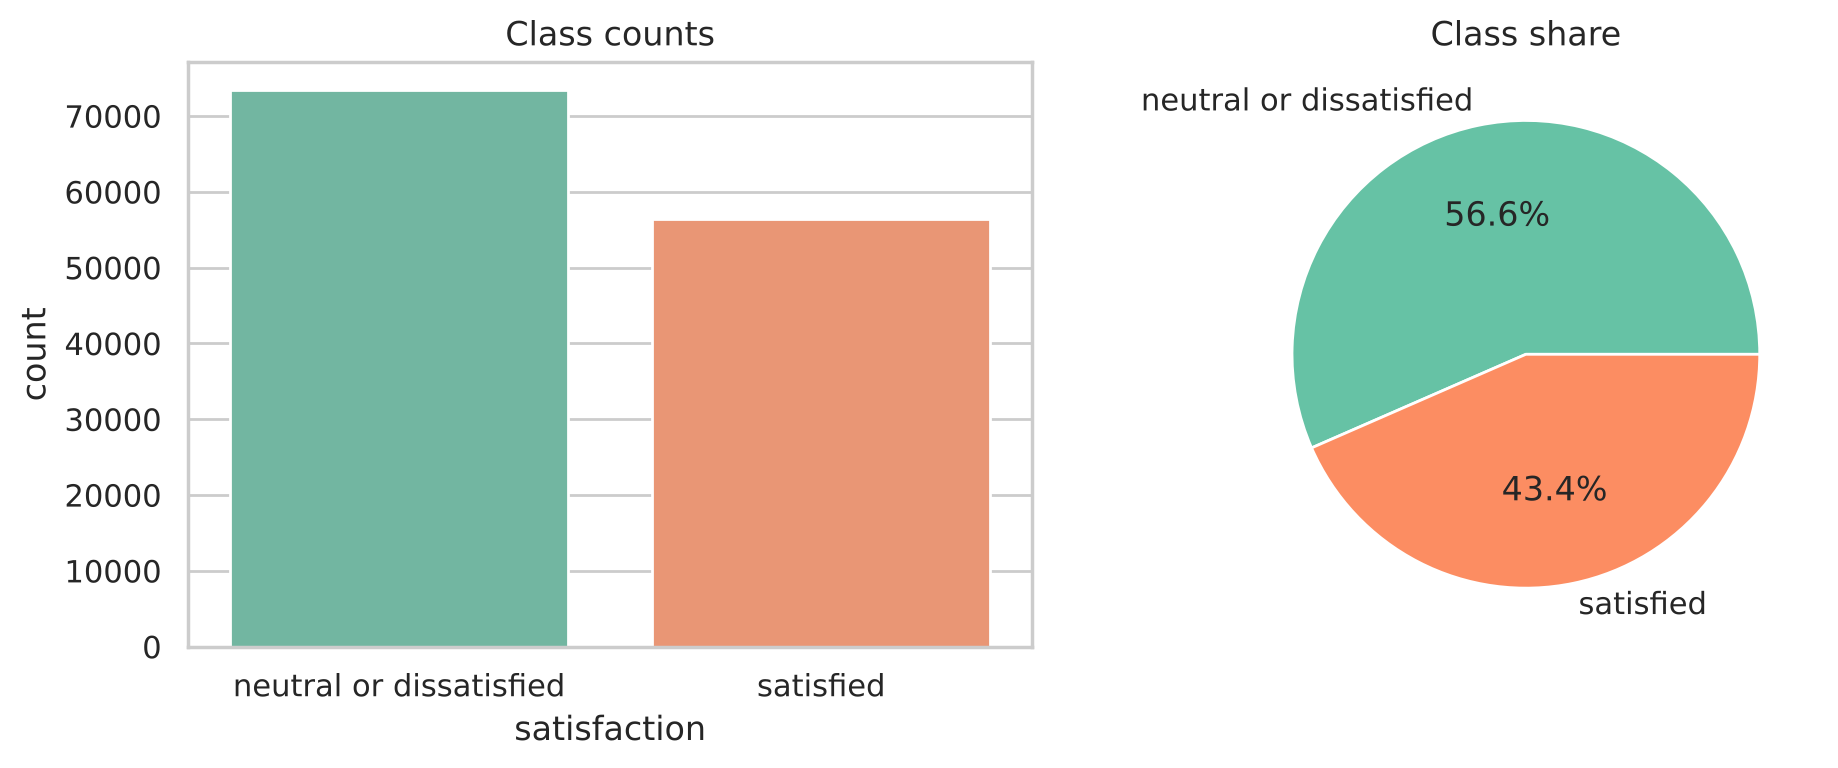

In [6]:
counts = df[target].value_counts()
pct = df[target].value_counts(normalize=True).mul(100).round(2)
dist = pd.DataFrame({"count": counts, "percentage": pct})
display(dist)
print(f"Imbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x=target, ax=ax[0], palette="Set2")
ax[0].set_title("Class counts")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", colors=sns.color_palette("Set2"))
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

**Observation:** the classes are only **mildly imbalanced** (about 56 % vs 44 %). No resampling is needed, but because accuracy alone can hide poor minority-class behaviour, AUC, Precision, Recall, F1 and MCC are reported as well. A **stratified** split is used so both train and test keep this same class ratio.

## 2. Data preprocessing

### 2.1 Missing values

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0]
print("Columns with missing values:")
display(pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(3)}))

Columns with missing values:


,missing,percent
Arrival Delay in Minutes,393,0.303


Only `Arrival Delay in Minutes` has missing values (about 0.3 %). Delays are heavily right-skewed with large outliers, so the **median** is a safer fill value than the mean. To avoid data leakage, the imputer is **not fitted here**; it is part of the pipeline which I did below and learns the median from the **training set only**.

So in the dataset 1–5 service-rating columns, a value of `0` means "not applicable / not rated" in this dataset. It is kept as a valid category on the ordinal scale. Just for clarity I am mentioning it here.

### 2.2 Duplicates

In [8]:
n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (129880, 23)


### 2.3 Train–test split (80:20, stratified, fixed seed)
The split is done **before** any imputation, encoding or scaling so that the test set never influences preprocessing.

In [9]:
X = df.drop(columns=[target])
y = (df[target] == "satisfied").astype(int)      # 1 = satisfied, 0 = neutral or dissatisfied

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nClass share (%) -> full / train / test")
print(pd.DataFrame({
    "full":  y.value_counts(normalize=True).mul(100).round(2),
    "train": y_train.value_counts(normalize=True).mul(100).round(2),
    "test":  y_test.value_counts(normalize=True).mul(100).round(2),
}))

Train: (103904, 22) | Test: (25976, 22)

Class share (%) -> full / train / test
               full  train   test
satisfaction                     
0             56.55  56.55  56.55
1             43.45  43.45  43.45


### 2.4 Encoding and scaling (fitted on training data only)
| Feature group | Treatment |
|---|---|
| Continuous + rating columns | median imputation (only matters for `Arrival Delay`) → `StandardScaler` |
| Categorical columns | `OneHotEncoder` (unknown categories ignored) |

Scaling is required for Logistic Regression and kNN (distance / gradient based) and is harmless for tree models. The same preprocessing is used for all five models so the comparison is fair. A `ColumnTransformer` inside a `Pipeline` guarantees that `fit` only sees training data and `transform` is simply applied to the test data.

In [10]:
numeric_cols = continuous_cols + rating_cols

def make_preprocessor():
    numeric_part = Pipeline([
        ("fill_median", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_part = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("num", numeric_part, numeric_cols),
        ("cat", categorical_part, categorical_cols),
    ])

# Quick look at the processed matrix (fitted on TRAIN only)
_prep = make_preprocessor().fit(X_train)
Xt_preview = _prep.transform(X_train)
print("Processed training matrix:", Xt_preview.shape)
print("Any NaN left after preprocessing:", np.isnan(Xt_preview).any())
print("Encoded feature names:", list(_prep.get_feature_names_out())[-9:])

Processed training matrix: (103904, 27)
Any NaN left after preprocessing: False
Encoded feature names: ['cat__Gender_Female', 'cat__Gender_Male', 'cat__Customer Type_Loyal Customer', 'cat__Customer Type_disloyal Customer', 'cat__Type of Travel_Business travel', 'cat__Type of Travel_Personal Travel', 'cat__Class_Business', 'cat__Class_Eco', 'cat__Class_Eco Plus']


## 3. Models and evaluation
### 3.1 Model configurations
| Model | Configuration |
|---|---|
| Logistic Regression | `max_iter=1000`, `solver='lbfgs'`, L2 penalty (default C=1.0) |
| Decision Tree | `max_depth=10`, `min_samples_leaf=5`, `criterion='gini'` (limited depth to reduce over-fitting) |
| kNN | `n_neighbors=5`, Euclidean distance, uniform weights |
| Naive Bayes | `GaussianNB` (features are continuous after scaling and one-hot encoding; Multinomial NB cannot take negative scaled values) |
| Random Forest | `n_estimators=200`, `max_depth=None`, `min_samples_leaf=1`, `n_jobs=-1` |

All models use `random_state=42` wherever the algorithm accepts one.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, solver="lbfgs", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2, n_jobs=-1),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}

### 3.2 Train all five models and compute the six metrics

In [12]:
import time
results, fitted, probs, preds = [], {}, {}, {}

for name, clf in models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    pipe.fit(X_train, y_train)                       # preprocessing + model fitted on TRAIN only

    y_prob = pipe.predict_proba(X_test)[:, 1]        # probability of 'satisfied'
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "ML Model Name": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "MCC":       matthews_corrcoef(y_test, y_pred),
    })
    fitted[name], probs[name], preds[name] = pipe, y_prob, y_pred
    print(f"{name:28s} done in {time.time() - t0:6.1f}s")

results_df = pd.DataFrame(results).set_index("ML Model Name").round(4)
results_df

Logistic Regression          done in    0.5s


Decision Tree                done in    0.7s


kNN                          done in    9.5s


Naive Bayes                  done in    0.4s


Random Forest (Ensemble)     done in   21.9s


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8741,0.9272,0.8699,0.8352,0.8522,0.7431
Decision Tree,0.9448,0.9870,0.9504,0.9211,0.9355,0.8877
kNN,0.9282,0.9703,0.9409,0.8907,0.9151,0.8539
Naive Bayes,0.8484,0.9159,0.8306,0.8179,0.8242,0.6911
Random Forest (Ensemble),0.9623,0.9940,0.9712,0.9413,0.9560,0.9235


Precision, Recall and F1 are computed for the positive class (`satisfied` = 1).

### 3.3 Comparison table

In [13]:
display(results_df.style.format("{:.4f}").background_gradient(cmap="YlGn", axis=0))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8741,0.9272,0.8699,0.8352,0.8522,0.7431
Decision Tree,0.9448,0.9870,0.9504,0.9211,0.9355,0.8877
kNN,0.9282,0.9703,0.9409,0.8907,0.9151,0.8539
Naive Bayes,0.8484,0.9159,0.8306,0.8179,0.8242,0.6911
Random Forest (Ensemble),0.9623,0.9940,0.9712,0.9413,0.9560,0.9235


## 4. Visual comparison

### 4.1 All six metrics for all models

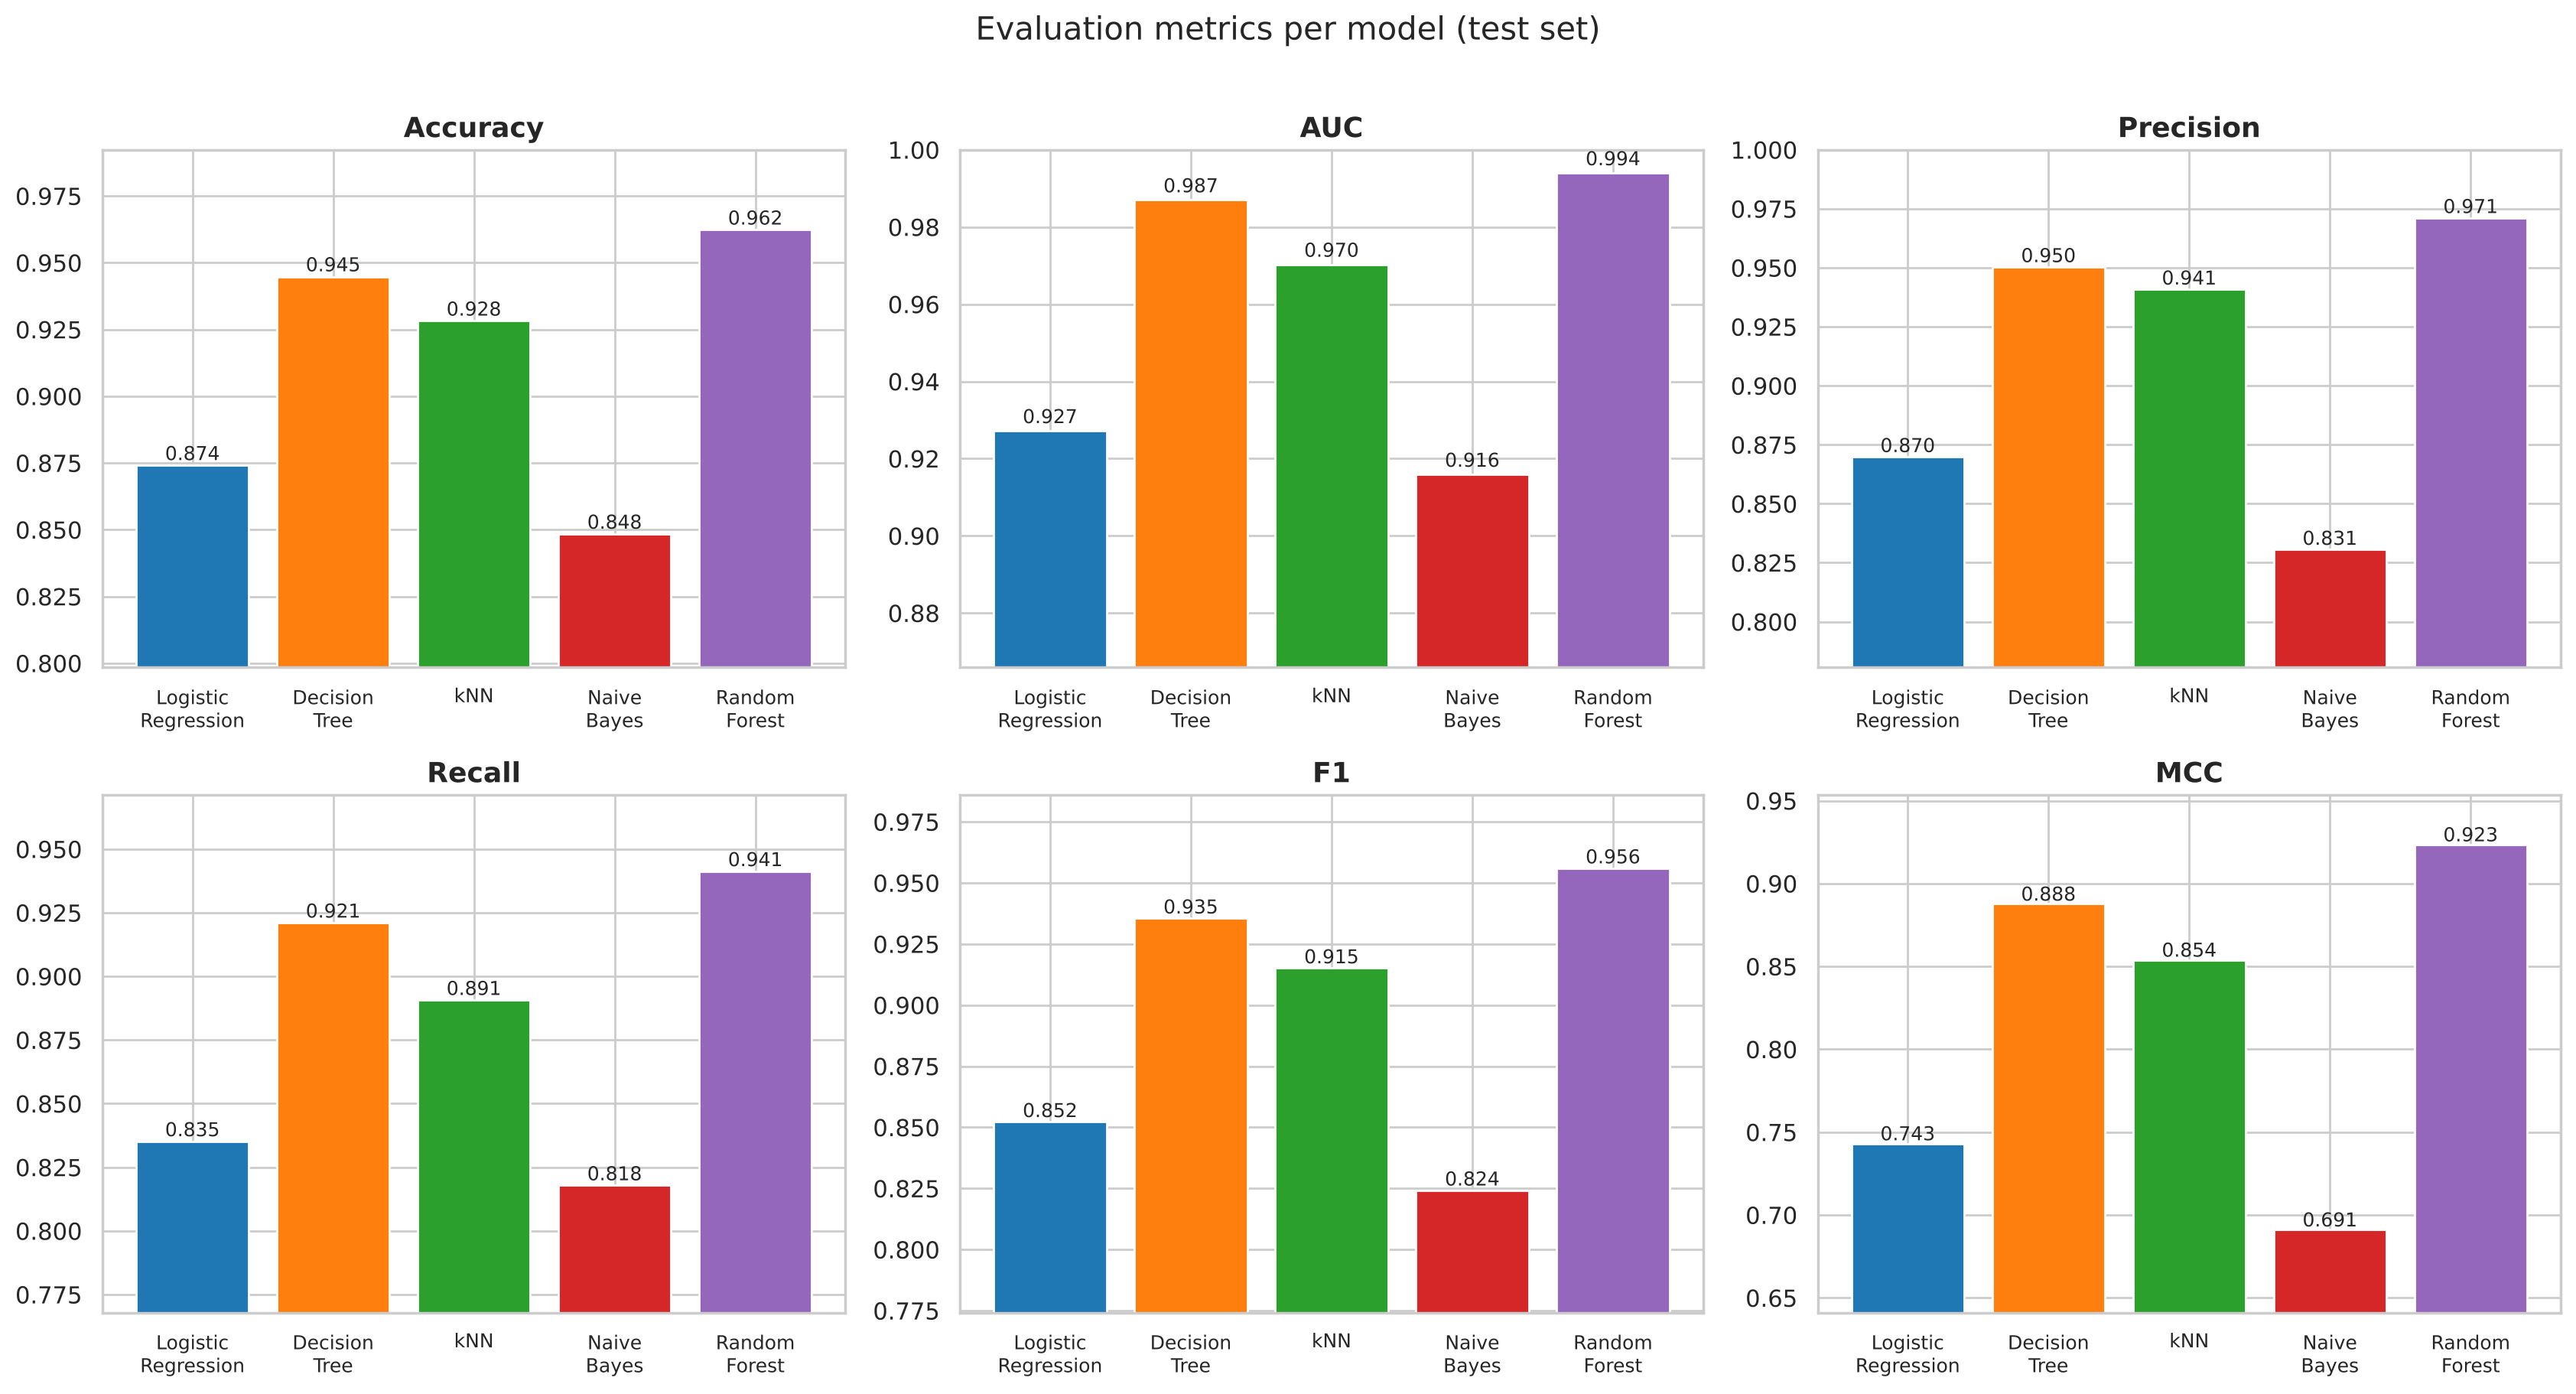

In [14]:
metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
palette = sns.color_palette("tab10", len(results_df))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, m in zip(axes.ravel(), metrics):
    vals = results_df[m]
    bars = ax.bar(range(len(vals)), vals.values, color=palette)
    ax.set_title(m, fontsize=13, fontweight="bold")
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels([n.replace(" (Ensemble)", "").replace(" ", "\n", 1) for n in vals.index], fontsize=9)
    lo = max(0, vals.min() - 0.05)
    ax.set_ylim(lo, min(1.0, vals.max() + 0.03))
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
plt.suptitle("Evaluation metrics per model (test set)", fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "metrics_bar_charts.png"), dpi=150, bbox_inches="tight")
plt.show()

### 4.2 Grouped comparison

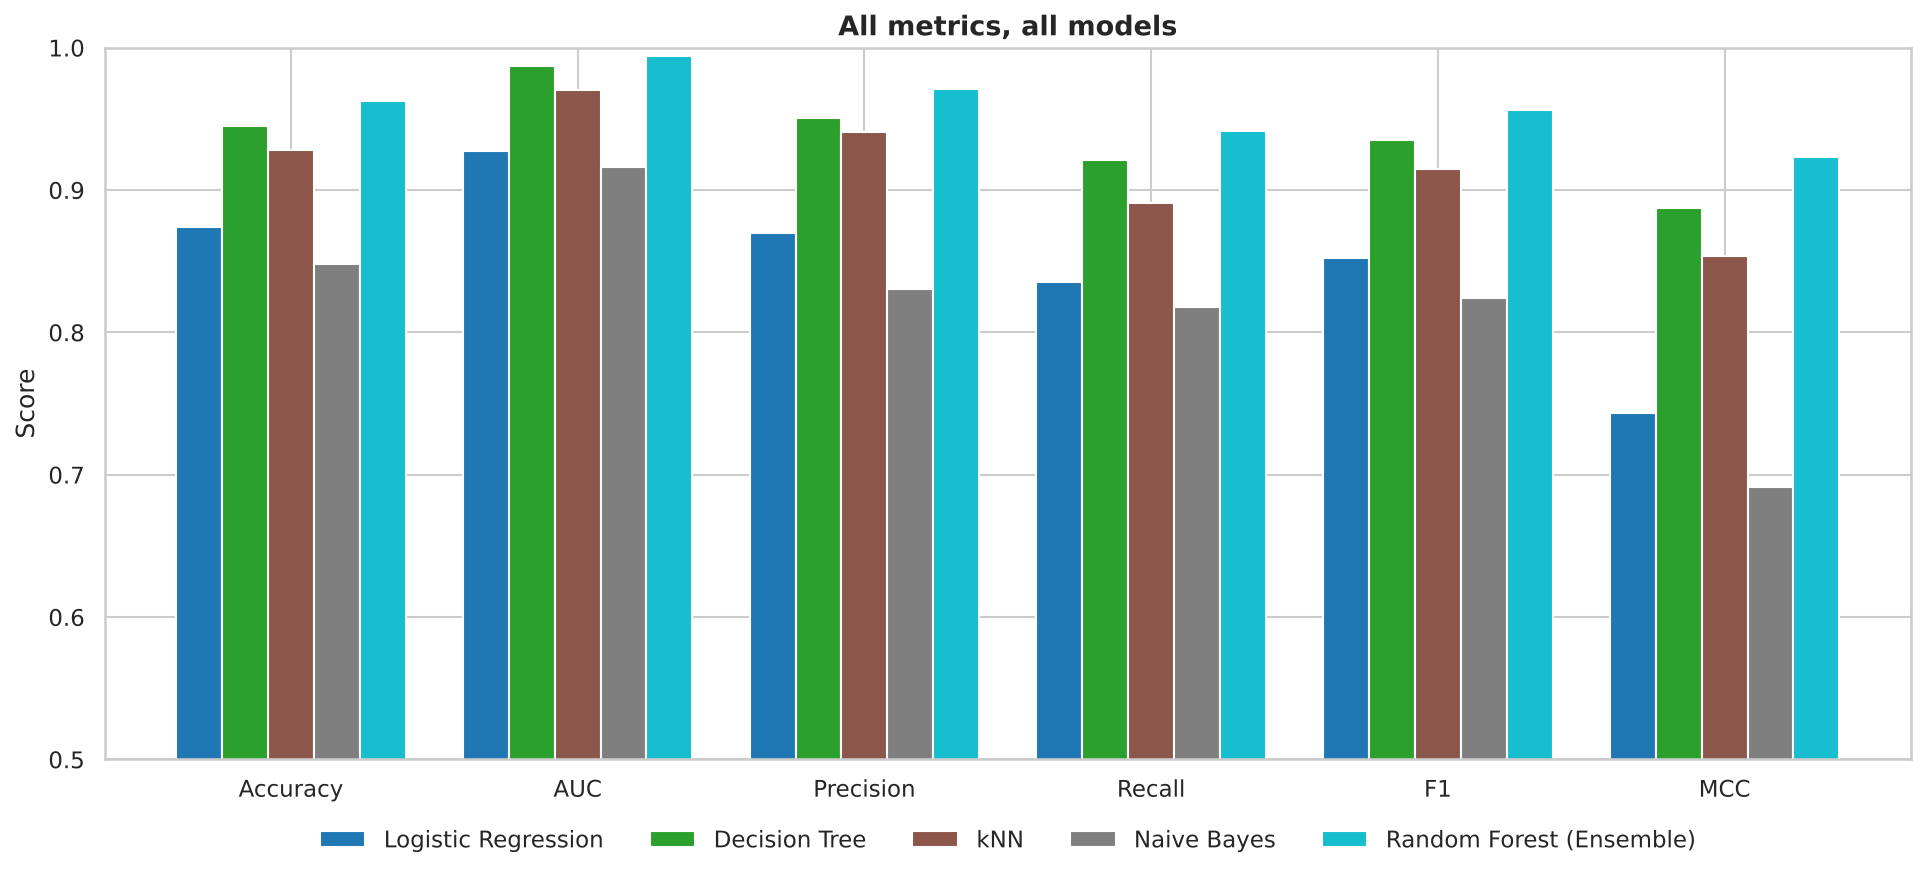

In [15]:
ax = results_df[metrics].T.plot(kind="bar", figsize=(13, 6), width=0.8, colormap="tab10")
ax.set_ylim(0.5, 1.0)
ax.set_title("All metrics, all models", fontsize=13, fontweight="bold")
ax.set_ylabel("Score"); ax.set_xlabel("")
plt.xticks(rotation=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=5, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "metrics_grouped.png"), dpi=150, bbox_inches="tight")
plt.show()

### 4.3 ROC curves

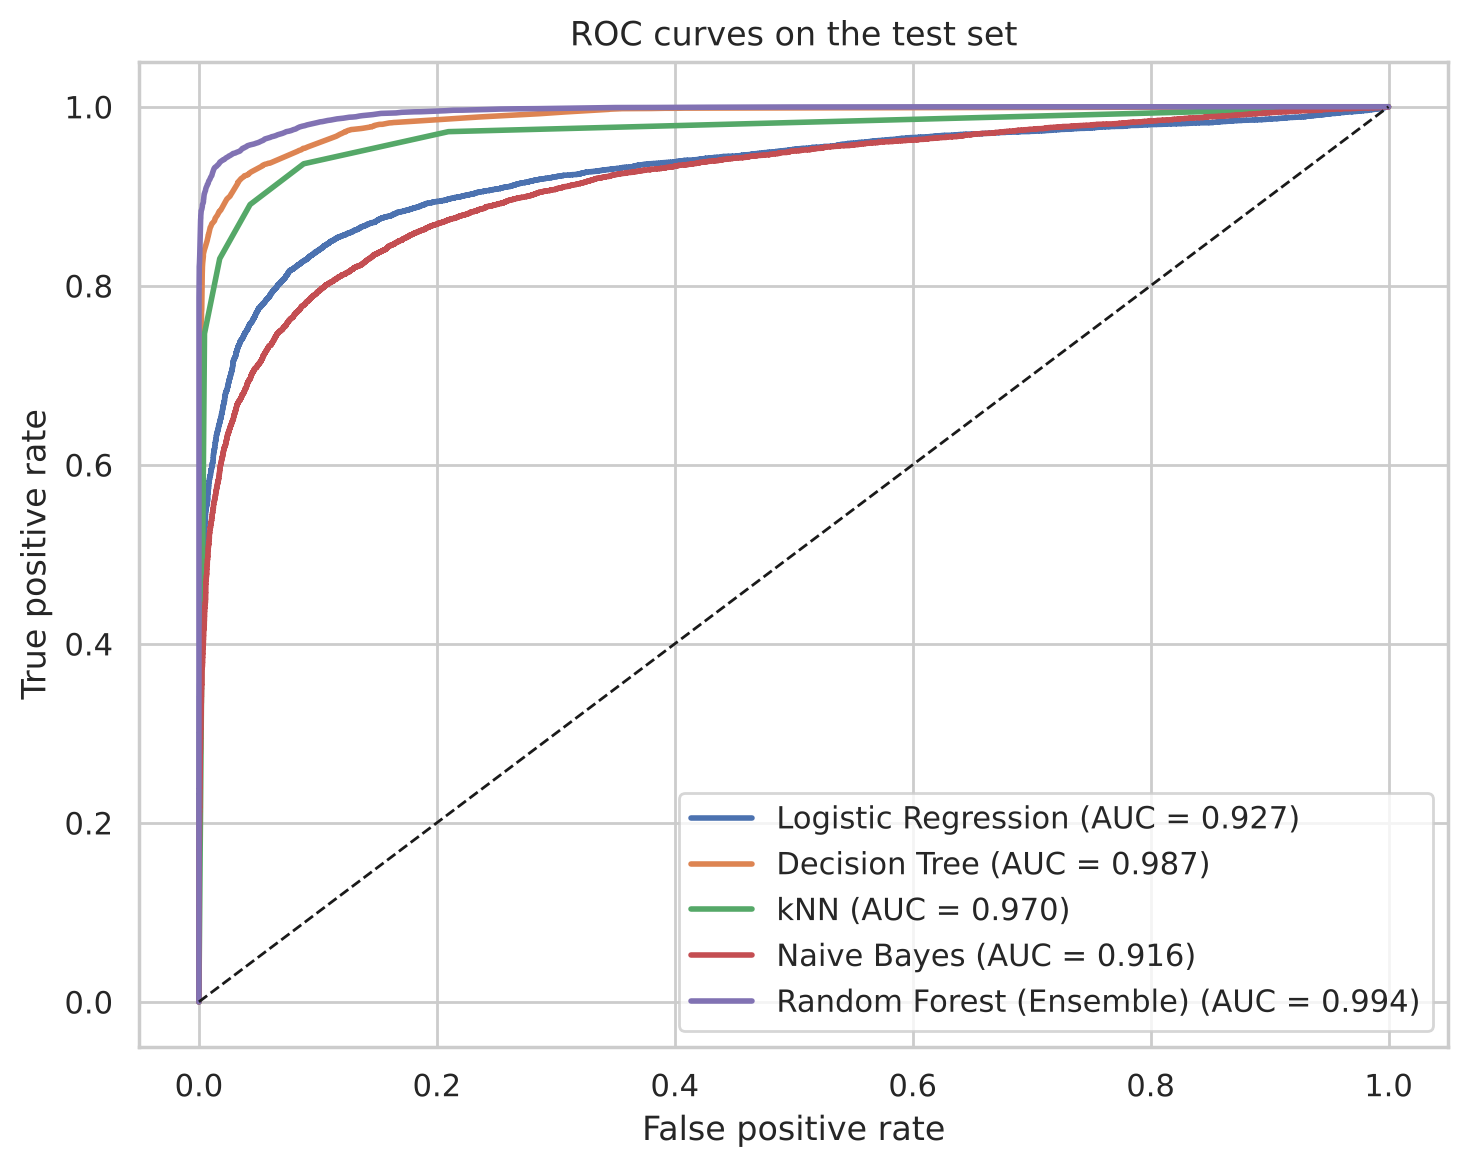

In [16]:
plt.figure(figsize=(7.5, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "roc_curves.png"), dpi=150)
plt.show()

### 4.4 Confusion matrices

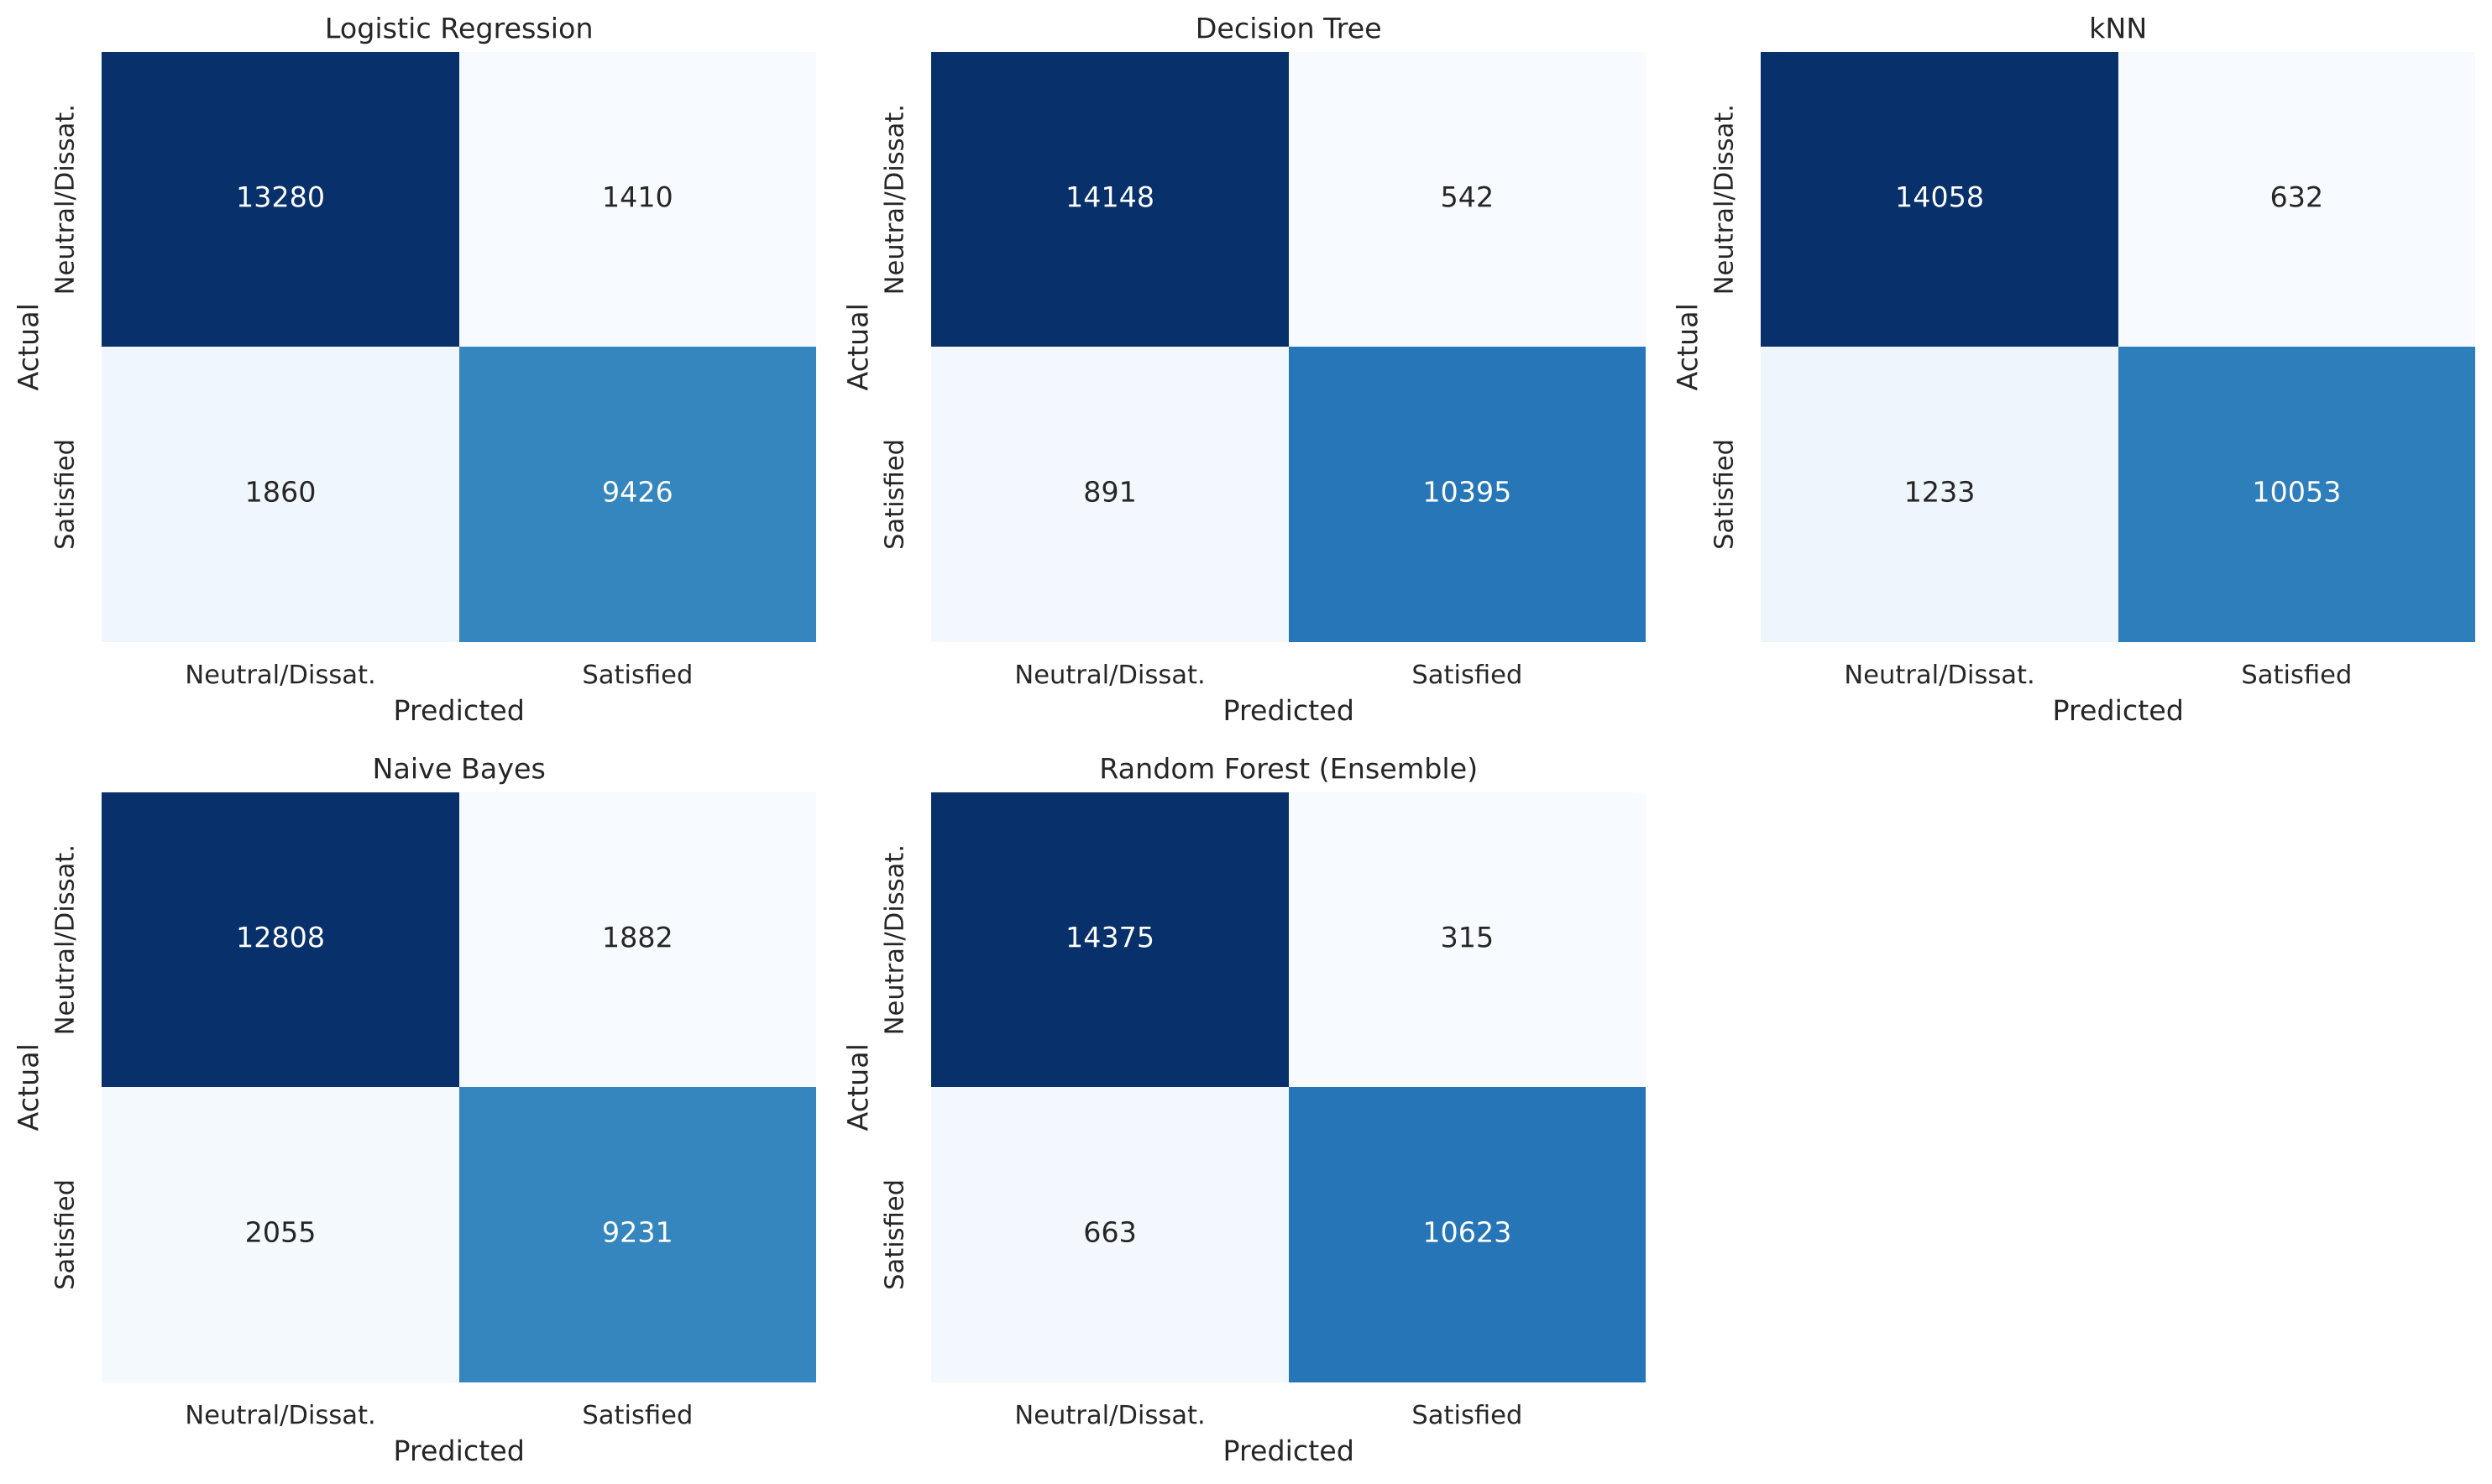

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, yp) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, yp)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Neutral/Dissat.", "Satisfied"], yticklabels=["Neutral/Dissat.", "Satisfied"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "confusion_matrices.png"), dpi=150)
plt.show()

### 4.5 Overall winner

In [18]:
# Rank each model on every metric (1 = best) and average the ranks
rank_table = results_df[metrics].rank(ascending=False, method="min")
rank_table["Average rank"] = rank_table.mean(axis=1)
display(rank_table.sort_values("Average rank"))

winner = rank_table["Average rank"].idxmin()
print(f"\nOverall winner by average rank: {winner}")
print(results_df.loc[winner])

,Accuracy,AUC,Precision,Recall,F1,MCC,Average rank
ML Model Name,,,,,,,
Random Forest (Ensemble),1.0,1.0,1.0,1.0,1.0,1.0,1.0
Decision Tree,2.0,2.0,2.0,2.0,2.0,2.0,2.0
kNN,3.0,3.0,3.0,3.0,3.0,3.0,3.0
Logistic Regression,4.0,4.0,4.0,4.0,4.0,4.0,4.0
Naive Bayes,5.0,5.0,5.0,5.0,5.0,5.0,5.0



Overall winner by average rank: Random Forest (Ensemble)
Accuracy     0.9623
AUC          0.9940
Precision    0.9712
Recall       0.9413
F1           0.9560
MCC          0.9235
Name: Random Forest (Ensemble), dtype: float64


### 4.6 Which features matter? (Random Forest importances)

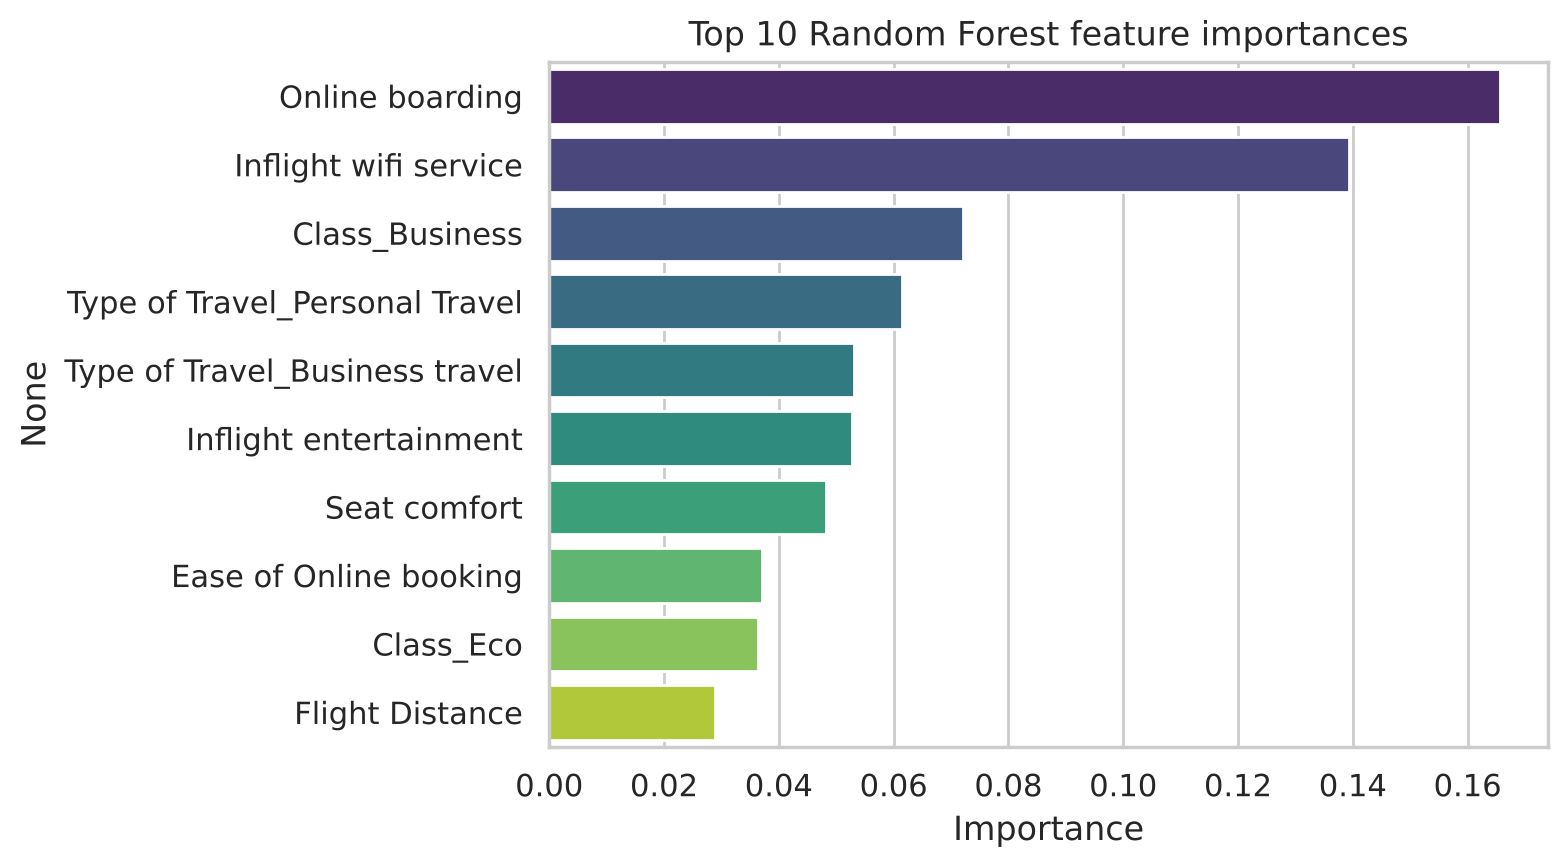

In [19]:
rf_pipe = fitted["Random Forest (Ensemble)"]
names = rf_pipe.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
imp = pd.Series(rf_pipe.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4.5))
sns.barplot(x=imp.values, y=imp.index, palette="viridis")
plt.title("Top 10 Random Forest feature importances")
plt.xlabel("Importance"); plt.ylabel(""); plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "rf_feature_importance.png"), dpi=150)
plt.show()

## 5. Save test data and trained models
`test_data.csv` is written to the repository root; the fitted pipelines (`*.joblib`) are saved in this `model/` folder.

In [20]:
# test data used in the experiments (the 20 % hold-out, with target label)
test_data = X_test.copy()
test_data[target] = np.where(y_test == 1, "satisfied", "neutral or dissatisfied")
test_data.to_csv(os.path.join(ROOT, "test_data.csv"), index=False)
print("test_data.csv saved:", test_data.shape)

# full pipelines (preprocessing + model) for each classifier
for name, pipe in fitted.items():
    fname = name.split(" (")[0].lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipe, os.path.join(MODEL_DIR, fname), compress=3)
    print("saved model/" + fname)

test_data.csv saved: (25976, 23)
saved model/logistic_regression.joblib
saved model/decision_tree.joblib
saved model/knn.joblib
saved model/naive_bayes.joblib


saved model/random_forest.joblib


## 6. Observations

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Accuracy about 0.874 and AUC about 0.927. As a linear model it cannot capture interactions such as "business-class travellers who rate online boarding highly", so it is clearly behind the non-linear models. Precision (0.870) is higher than recall (0.835), so it misses some satisfied passengers. It is fast and interpretable, so it is a good baseline. |
| **Decision Tree** | Accuracy about 0.945 and AUC 0.987. A depth-limited tree (`max_depth=10`) captures non-linear rules and interactions and is far better than Logistic Regression. It is easy to explain, but a single tree is less stable than an ensemble and is beaten by Random Forest on every metric. |
| **kNN** | Accuracy about 0.928 and AUC 0.970. Works well once features are scaled, but recall (0.891) is lower than the tree models. It is the slowest at prediction time because every test point is compared with about 104k training rows, and it stores the whole training set in the saved model. |
| **Naive Bayes** | Weakest model: accuracy about 0.848 and MCC about 0.691. The independence assumption does not hold here because many service ratings are strongly correlated (for example wifi, online boarding and booking ease), and one-hot features are not Gaussian. It trains almost instantly but trades accuracy for speed. |
| **Random Forest (Ensemble)** | Best on all six metrics: accuracy about 0.962, AUC 0.994, precision 0.971, recall 0.941, F1 0.956 and MCC 0.924. Averaging 200 trees reduces the variance of a single tree. The most important features are online boarding, inflight wifi service, class and type of travel. |
| **Overall winner for this dataset** | **Random Forest**. It ranks first on Accuracy, AUC, Precision, Recall, F1 and MCC. Ranking of the rest: Decision Tree, kNN, Logistic Regression, Naive Bayes. The classes are only mildly imbalanced (about 56:44), so accuracy and the class-sensitive metrics (F1, MCC) agree on this ordering. |

**Overall:** non-linear, tree-based methods work best here (Random Forest > Decision Tree > kNN), while the two models with strong assumptions (linear boundary for Logistic Regression, feature independence for Naive Bayes) perform worst. Results are for one fixed 80:20 split with seed 42 and no hyper-parameter tuning, so small differences between close models should be read with that in mind.